# Part 1: Import Packages

In [1]:
%pip install ucimlrepo

# Data Processing
import numpy as np
import pandas as pd

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Calibration
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import CalibrationDisplay
from sklearn.frozen import FrozenEstimator

# Model Evaluation
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import brier_score_loss, log_loss

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Data Source
from ucimlrepo import fetch_ucirepo

To ensure our experiment is reproducible, we will set a single seed (42) to be used throughout the training.

In [2]:
SEED = 42

Missing a spam email (**False Negative - FN**) is generally not as costly as missing a real, potentially critical email (**False Positive - FP**). Consequently, we set the cost of a false positive to be significantly higher than a false negative ($C_{FP} > C_{FN}$).

In [3]:
# Fixed parameters
N_DRAWS = 50
C_FPS = (1, 5, 20)
C_FN = 1
CALIBRATION_DRAWS = (100, 250, 500, 1000)

# Part 2: Importing Dataset

The dataset was loaded from the UCI repository as a feature table plus a target column. From [UCI](#https://archive.ics.uci.edu/dataset/94/spambase), Spambase has 4,601 rows and 57 numeric features, with no missing values.

In [4]:
# fetch spam dataset
spambase = fetch_ucirepo(id=94)
spam_df = pd.concat((spambase.data.features, spambase.data.targets), axis=1)

# variable information
print(spambase.variables)

                          name     role        type demographic  \
0               word_freq_make  Feature  Continuous        None   
1            word_freq_address  Feature  Continuous        None   
2                word_freq_all  Feature  Continuous        None   
3                 word_freq_3d  Feature  Continuous        None   
4                word_freq_our  Feature  Continuous        None   
5               word_freq_over  Feature  Continuous        None   
6             word_freq_remove  Feature  Continuous        None   
7           word_freq_internet  Feature  Continuous        None   
8              word_freq_order  Feature  Continuous        None   
9               word_freq_mail  Feature  Continuous        None   
10           word_freq_receive  Feature  Continuous        None   
11              word_freq_will  Feature  Continuous        None   
12            word_freq_people  Feature  Continuous        None   
13            word_freq_report  Feature  Continuous        Non

In [5]:
# See the first 5 spam samples
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [6]:
# See data types in each column
spam_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

## 2.1. Correlation Matrix

We will use a **correlation matrix** to identify features that are highly correlated with each other and decide which columns to be used for our models.

In [7]:
correlation_matrix = spam_df.corr(numeric_only=True)

# Plot heatmap of correlation matrix
fig = go.Figure(data=go.Heatmap(
   z=correlation_matrix,
   x=correlation_matrix.columns,
   y=correlation_matrix.index,
   colorscale='RdBu_r',
   text=correlation_matrix.round(2),
   texttemplate='%{text}',
   textfont={"size": 10},
   hoverongaps=False,
   zmin=-1
))

fig.update_layout(
   width=2500,
   height=2500,
   title='Correlation Matrix Heatmap',
   xaxis_title='',
   yaxis_title='',
   yaxis=dict(autorange='reversed')
)

We observed features that are highly correlated with each other:
- `word_freq_857` and `word_freq_415` --> $\rho=1$ (correlation)
- `word_freq_direct` and `word_freq_857` --> $\rho=0.85$
- `word_freq_direct` and `word_freq_415` --> $\rho=0.85$

Since the first pair has a perfect correlation, we can safely drop the column `word_freq_857` from the dataset. Even though the remaining pairs are highly correlated, we want to keep them for Random Forest because ensemble models (in this case, **bagging**) can handle correlated features well. However, multicollinearity will dillute the coefficients in Logistic Regression, so (later) we will drop the column `word_freq_direct` only for training this baseline model.

In [8]:
spam_df.drop('word_freq_857', axis=1, inplace=True)

In [9]:
# Check if there are any duplicate rows in the dataset
spam_df[spam_df.duplicated(keep=False)]

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
24,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4441,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4537,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,6,0
4541,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,2,0


## 2.2. Grouping

In real scenarios, spam messages often have the same exact information, so duplicate samples also serve as a signal of repeating events. Thus, instead of simply removing them, we will group the duplicates and giving unique samples with unique ids.

In [10]:
spam_feature_cols = [col for col in spam_df.columns if col != 'Class']
X_spam, y_spam = spam_df[spam_feature_cols], spam_df['Class']

# Check class balance
print(f"Original Balance: {y_spam.mean():.2%} spam")

# Creating group ids (identical rows share the same id)
spam_groups = spam_df.groupby(spam_feature_cols).ngroup()
print(f"{len(spam_df)} samples --> {spam_groups.max() + 1} groups")

# Count identical rows with conflicting labels
conflicts = spam_df.groupby(spam_groups)['Class'].nunique().gt(1).sum()
print(f"Groups with conflicting labels: {conflicts}")

Original Balance: 39.40% spam
4601 samples --> 4207 groups
Groups with conflicting labels: 3


## 2.3. Splitting

Due to the class imbalance, we want to use a stratified split. We also want to split the **duplicate-grouped** dataset into training, calibration, validation, and testing sets, so we will use `StrateifiedGroupKFold` to satisfy all of these criterions.

In [11]:
# 10 stratified folds that never split a group
fold = np.empty(len(spam_df), dtype=int)
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
for k, (_, idx) in enumerate(sgkf.split(X_spam, y_spam, spam_groups)):
    fold[idx] = k

# Split 40% train, 30% calibration pool, 10% validation, 20% test
spam_parts = np.select([fold < 4, fold < 7, fold < 8], ['train', 'cal', 'val'], 'test')

# Select rows from X_spam that correspond to rows in `spam_parts` that are labelled as 'train'
X_spam_train, y_spam_train = X_spam[spam_parts == 'train'], y_spam[spam_parts == 'train']

X_spam_cal,   y_spam_cal   = X_spam[spam_parts == 'cal'],   y_spam[spam_parts == 'cal']
X_spam_val,   y_spam_val   = X_spam[spam_parts == 'val'],   y_spam[spam_parts == 'val']
X_spam_test,  y_spam_test  = X_spam[spam_parts == 'test'],  y_spam[spam_parts == 'test']

# Check every group belongs to exactly one set, and class balance is preserved
assert (pd.Series(spam_parts).groupby(spam_groups.values).nunique() == 1).all()
print(pd.Series(y_spam.values).groupby(spam_parts).agg(['size', 'mean']))

       size      mean
cal    1404  0.397436
test    955  0.392670
train  1791  0.392518
val     451  0.392461


# Part 3: Logistic Regression

## 3.1. Custom Functions

### 3.1.1. Estimator Pipeline

Preprocessing (one-hot encoding and scaling) is wrapped in a `Pipeline` with the classifier. During cross-validation, the encoder and scaler are refit on each training fold only, so no information from the validation fold leaks into preprocessing.

<u>Idea:</u> Automatically perform `.fit_transform()` on the training set and `.transform()` on the held-out data during preprocessing.

In [12]:
def create_pipeline(model, categorical_features, numerical_features, drop_features=None, drop=None):
    """
    Creates a machine learning pipeline with automated preprocessing and classification.

    Parameters:
    -----------
    model : estimator object
        The scikit-learn classifier model to be placed at the end of the pipeline.

    categorical_features : list of str
        List of column names containing categorical features to be processed with OneHotEncoder.

    numerical_features : list of str
        List of column names containing numerical features to be processed with StandardScaler.

    drop_features : list of str, default=None
        Optional list of column names that should be dropped from the feature set.

    drop : str, default=None
        Specifies the drop argument for the OneHotEncoder (e.g., 'first' to drop the first category).

    Returns:
    --------
    pipeline : sklearn.pipeline.Pipeline
        The configured machine learning pipeline.
    """
    transformers = [
        ('cat', OneHotEncoder(handle_unknown='ignore', drop=drop), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]

    if drop_features:
        transformers.append(('drop_cols', 'drop', drop_features))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder='passthrough',
        force_int_remainder_cols=False
    )

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    return pipeline

### 3.1.2. Score Function

Compute the Brier and Log-Loss scores of the model, as well as its expected cost, to evaluate the model's performance.

In [13]:
def score(model, X, y, c_fp, c_fn):
    """
    Computes classification evaluation metrics including Brier score, log loss, and expected cost.

    Parameters:
    -----------
    model : estimator object
        The trained classifier or calibrated pipeline to evaluate.
    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        The input feature matrix for making predictions.
    y : array-like of shape (n_samples,)
        The true binary labels.
    c_fp : float
        The cost weight penalty associated with a False Positive error.
    c_fn : float
        The cost weight penalty associated with a False Negative error.

    Returns:
    --------
    brier : float
        The Brier score loss.
    logloss : float
        The log loss score.
    cost : float
        The average expected decision cost per instance.
    """
    threshold = c_fp / (c_fp + c_fn)
    p = model.predict_proba(X)[:, 1]
    pred = p > threshold
    cost = (c_fp * np.sum(pred & (y == 0)) + c_fn * np.sum(~pred & (y == 1))) / len(y)
    return brier_score_loss(y, p), log_loss(y, p), cost

### 3.1.3. Calibration Simulation Process

Runs a repeated calibration simulation drawing random subsets of different sizes from the calibration pool. For each draw, it fits both Platt scaling (`sigmoid`) and `isotonic` regression, and evaluates validation cost distributions across multiple False Positive cost ratios $(C_{FP}$).

<u>Idea:</u> Isolate the impact of calibration sample size ($n$) and cost weights while removing sample-draw variance by using the same underlying subsets for all evaluations.

In [14]:
def run_calibration_experiment(model, X_train, y_train, X_cal, y_cal, X_val, y_val):
    """
    Runs a repeated calibration simulation drawing random subsets of different sizes
    from the calibration set, fitting Platt scaling (sigmoid) and isotonic calibrators,
    and scoring them across multiple False Positive cost ratios.

    Parameters:
    -----------
    model : estimator object
        The pre-trained baseline classifier model.
    X_train : {array-like, sparse matrix}
        The training feature matrix.
    y_train : array-like
        The training target labels.
    X_cal : {array-like, sparse matrix}
        The calibration pool feature matrix.
    y_cal : array-like
        The calibration pool target labels.
    X_val : {array-like, sparse matrix}
        The validation feature matrix.
    y_val : array-like
        The validation target labels.

    Returns:
    --------
    df_results : pandas.DataFrame
        DataFrame of performance logs with columns ['c_fp', 'method', 'n', 'brier', 'logloss', 'cost'].
    """
    rng = np.random.default_rng(SEED)
    rows = []

    # Evaluate the uncalibrated baseline first across all cost ratios
    for c_fp in C_FPS:
        rows.append((c_fp, 'none', 0, *score(model, X_val, y_val, c_fp, C_FN)))

    # Consistent draws across all cost ratios for each calibration size
    for n in CALIBRATION_DRAWS:
        for _ in range(N_DRAWS):
            # Draw a single consistent calibration sample
            idx = rng.choice(len(y_cal), n, replace=False)
            X_cal_sub, y_cal_sub = X_cal.iloc[idx], y_cal.iloc[idx]

            for method in ('sigmoid', 'isotonic'):
                # Fit the calibrator
                cal = CalibratedClassifierCV(FrozenEstimator(model), method=method)
                cal.fit(X_cal_sub, y_cal_sub)

                # Evaluate the identical calibrated model across all cost ratios
                for c_fp in C_FPS:
                    rows.append((c_fp, method, n, *score(cal, X_val, y_val, c_fp, C_FN)))

    df_results = pd.DataFrame(rows, columns=['c_fp', 'method', 'n', 'brier', 'logloss', 'cost'])
    for col in ['c_fp', 'n', 'brier', 'logloss', 'cost']:
        df_results[col] = pd.to_numeric(df_results[col], errors='coerce')

    return df_results

## 3.2 Model Training

For the baseline, we will tune the hyperparameter `C` of the Logistic Regression model using the stratified 5-fold CV on the **training set** (`X_spam_train`, `y_spam_train`). We then draw a **reliability diagram** of the model evaluated on the **validation set** (`X_spam_val`, `y_spam_val`).

Best CV Log Loss: 0.2209
Best Hyperparameters: {'classifier__C': 1}


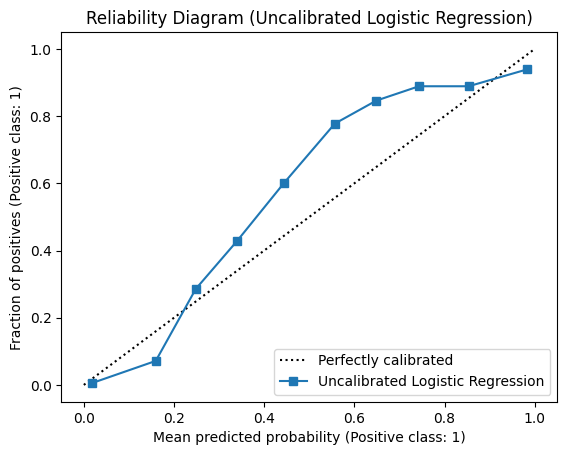

In [15]:
# Tune and train the logistic regression model on training data
train_group = spam_groups[spam_parts == 'train']
cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X_spam_train, y_spam_train, train_group))

# Drop the highly-correlated column 'word_freq_direct'
lr_numerical_features = [col for col in spam_feature_cols if col != 'word_freq_direct']
spam_lr = create_pipeline(LogisticRegression(max_iter=2000, random_state=SEED),
                        [], lr_numerical_features, drop_features=['word_freq_direct'], drop='first')

param_grid = {'classifier__C': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(spam_lr, param_grid, cv=cv, scoring='neg_log_loss', n_jobs=-1)
grid_search.fit(X_spam_train, y_spam_train)

# Output tuning results
print(f"Best CV Log Loss: {abs(grid_search.best_score_):.4f}")
print("Best Hyperparameters:", grid_search.best_params_)

# Get the best model
spam_lr = grid_search.best_estimator_

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_lr, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Logistic Regression")
plt.title("Reliability Diagram (Uncalibrated Logistic Regression)")
plt.show()

## 3.3. Model Calibration

In this section, we evaluate calibration techniques on our tuned Logistic Regression baseline. For each cost ratio, we randomly draw subsamples of sizes $n \in \{100, 250, 500, 1000\}$ from the **calibration set** (`X_spam_cal`, `y_spam_cal`) and fit both Platt Scaling (`sigmoid`) and `isotonic` regression. We then compute Brier scores, Log-Loss, and expected decision costs on the **validation set** (`X_spam_val`, `y_spam_val`) using the `score()` function. This procedure is repeated over 50 random calibration draws to capture performance distributions.

**Note**: $n=0$ represents the uncalibrated model baseline. We wrap our baseline model inside a `FrozenEstimator` to ensure that `CalibratedClassifierCV` uses the calibration set strictly to learn probability corrections without altering the weights already learned on the training set.

In [16]:
# Run the calibration experiment using our custom function
lr_calibration_results = run_calibration_experiment(
    model=spam_lr,
    X_train=X_spam_train,
    y_train=y_spam_train,
    X_cal=X_spam_cal,
    y_cal=y_spam_cal,
    X_val=X_spam_val,
    y_val=y_spam_val
)

print(lr_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0647  0.0074  0.6209  0.3640  0.0814  0.0124
              250   0.0608  0.0029  0.3186  0.1512  0.0761  0.0066
              500   0.0596  0.0016  0.2325  0.0553  0.0747  0.0042
              1000  0.0593  0.0008  0.2079  0.0025  0.0748  0.0011
     none     0     0.0605     NaN  0.2487     NaN  0.0754     NaN
     sigmoid  100   0.0796  0.0183  0.2774  0.0444  0.1020  0.0389
              250   0.0725  0.0065  0.2598  0.0139  0.0905  0.0118
              500   0.0711  0.0043  0.2556  0.0090  0.0879  0.0080
              1000  0.0711  0.0021  0.2543  0.0038  0.0894  0.0048
5    isotonic 100   0.0647  0.0074  0.6209  0.3640  0.2200  0.0365
              250   0.0608  0.0029  0.3186  0.1512  0.2192  0.0294
              500   0.0596  0.0016  0.2325  0.0553  0.2063  0.

## 3.4. Plotting Costs

We will then generate plots with error bars to visualize how different calibration set sizes impact the validation cost of the Logistic Regression model compared to its uncalibrated baseline.

In [17]:
def plot_calibration_costs(calibration_results, model_name):
    """
    Plots the change in validation cost vs calibration size for each cost ratio (c_fp).

    Parameters:
    -----------
    calibration_results : pandas.DataFrame
        DataFrame containing experiment logs with columns ['c_fp', 'method', 'n', 'cost', ...].
    model_name : str
        A label/name for the model used in the plot titles (e.g., 'LR' or 'RF').
    """
    base_model = calibration_results.query("method == 'none'")

    # Group and calculate delta cost for each cost ratio (c_fp)
    delta_rows = []
    for c_fp in base_model['c_fp'].unique():
        base_cost = base_model[base_model['c_fp'] == c_fp]['cost'].iloc[0]
        sub_cal = calibration_results.query("n > 0 & c_fp == @c_fp").copy()
        sub_cal['delta'] = sub_cal['cost'] - base_cost
        delta_rows.append(sub_cal)

    delta_cost = pd.concat(delta_rows).groupby(['c_fp', 'method', 'n']).delta.agg(['mean', 'std']).reset_index()

    # Plotting changes in validation cost vs calibration size for each cost ratio
    unique_c_fps = sorted(delta_cost['c_fp'].unique())
    fig, axes = plt.subplots(1, len(unique_c_fps), figsize=(6 * len(unique_c_fps), 5), sharey=False)

    if len(unique_c_fps) == 1:
        axes = [axes]

    for i, c_fp in enumerate(unique_c_fps):
        ax = axes[i]
        data_subset = delta_cost[delta_cost['c_fp'] == c_fp]
        for method, delta in data_subset.groupby('method'):
            ax.errorbar(delta.n, delta['mean'], delta['std'], marker='o', capsize=4, label=method)

        ax.axhline(0, ls='--', c='gray')
        ax.set_xscale('log')
        ax.set_xticks(sorted(delta_cost['n'].unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_title(f'{model_name} - Cost Ratio C_FP={c_fp}')
        ax.set_xlabel('Calibration set size')
        ax.set_ylabel('Change in validation cost')
        ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

### 3.4.1. Plots

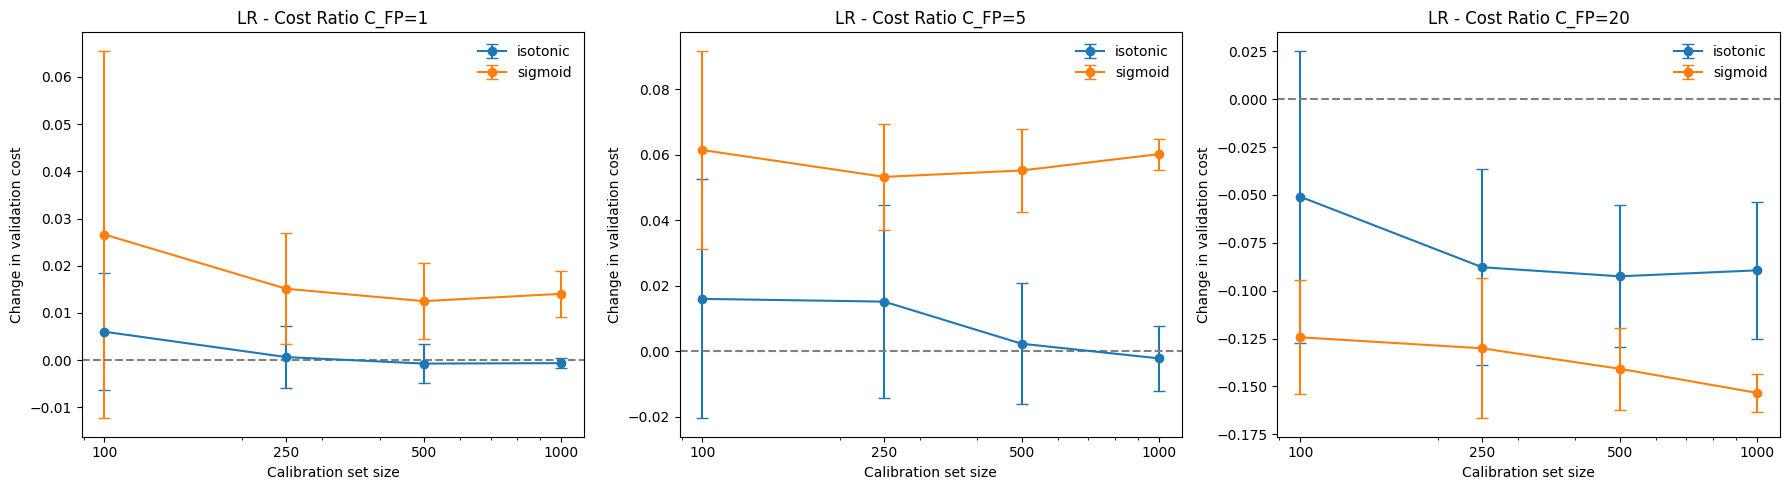

In [18]:
plot_calibration_costs(lr_calibration_results, 'LR')

Analyzing the plots with validation cost change error bars for Logistic Regression reveals several clear patterns:

- **Sigmoid Calibration (Platt Scaling)**:
  - For symmetric and moderate cost ratios ($C_{FP}=1, 5$), Platt scaling consistently increases validation costs compared to the uncalibrated baseline.
  - At the highly asymmetric cost ratio ($C_{FP}=20$), Sigmoid calibration successfully decreases validation costs across all calibration sample sizes ($n$), indicating that probability flattening aligns well with extreme decision thresholds. Note that it performs better than isotonic calibration at this extreme threshold.

- **Isotonic Calibration**:
  - At small calibration sizes ($n=100, 250$), Isotonic calibration exhibits high variance and overfits, leading to increased expected costs.
  - At $C_{FP}=5$ and $C_{FP}=20$, Isotonic calibration curves steadily descend below the baseline ($y=0$) as $n$ increases, showing that non-parametric methods become highly effective with sufficient calibration data (particularly at $n=1000$).

## 3.5. Confidence Interval

We will further analyze the effect of calibration by constructing a paired **bootstrap confidence interval** for the change in validation cost (`calibrated_cost - uncalibrated_cost`) over the 50 random calibration draws. Under this framework, if the 95% confidence interval contains zero, the calibration method's effect is considered a **tie** (statistically indistinguishable from the baseline).

Since duplicate feature rows represent identical messages that share the same characteristics (and are grouped together), treating them as independent observations during resampling would violate the assumption of independence. Standard bootstrapping would repeatedly sample individual rows, breaking the structural duplicate-grouped relationships and artificially shrinking our standard errors. By using a **group-paired bootstrap** (sampling unique group IDs with replacement and keeping all matching duplicate rows together), we accurately preserve the group structure, yielding statistically valid and honest confidence intervals.

In [19]:
def bootstrap_ci(cal_res, group_series, partition_series, target_part='val'):
    """
    Compute a bootstrap interval for the paired difference (calibrated_cost - uncalibrated_cost)
    using an optimized group-paired bootstrap over the specified partition to respect duplicate groups.

    Parameters:
    -----------
    cal_res : pandas.DataFrame
        DataFrame containing experiment logs with columns ['c_fp', 'method', 'n', 'cost', ...].

    group_series : pandas.Series or array-like
        Series matching the dataset rows indicating which duplicate group index each row belongs to.

    partition_series : pandas.Series or array-like
        Series matching the dataset rows indicating which partition ('train', 'cal', 'val', 'test') each row belongs to.

    target_part : str, default='val'
        The string identifier of the partition on which the validation evaluation is performed.

    Returns:
    --------
    df_ci : pandas.DataFrame
        DataFrame summarizing the bootstrap confidence intervals with columns
        ['c_fp', 'method', 'n', 'mean_difference', '95% CI Lower', '95% CI Upper', 'outcome'].
    """
    # Align group identifiers and indices matching the target evaluation partition
    target_groups = pd.Series(group_series)[partition_series == target_part].reset_index(drop=True)
    unique_groups = target_groups.unique()
    n_groups = len(unique_groups)

    # Pre-compute dictionary of group to row-index list mapping
    group_idx_map = {}
    for g in unique_groups:
        group_idx_map[g] = target_groups[target_groups == g].index.tolist()

    bootstrap_results = []
    base_model = cal_res.query("method == 'none'")
    rng = np.random.default_rng(SEED)

    for c_fp in cal_res['c_fp'].unique():
        base_cost = base_model[base_model['c_fp'] == c_fp]['cost'].iloc[0]

        for method in ('sigmoid', 'isotonic'):
            for n in CALIBRATION_DRAWS:
                # Retrieve the validation costs for this specific setting
                subset = cal_res[(cal_res.method == method) & (cal_res.n == n) & (cal_res.c_fp == c_fp)]
                differences = subset.cost.values - base_cost

                if len(differences) == 0:
                    continue

                boot_means = []
                for _ in range(10_000):
                    # Sample group IDs with replacement
                    sampled_groups = rng.choice(unique_groups, size=n_groups, replace=True)

                    # Retrieve indices quickly via dictionary lookup
                    sampled_indices = []
                    for g in sampled_groups:
                        sampled_indices.extend(group_idx_map[g])

                    # Adjust indices to stay within the boundaries of the `differences` array
                    sampled_indices = [idx % len(differences) for idx in sampled_indices]
                    boot_sample = differences[sampled_indices]
                    boot_means.append(np.mean(boot_sample))

                ci_lower = np.percentile(boot_means, 2.5)
                ci_upper = np.percentile(boot_means, 97.5)
                mean_diff = np.mean(differences)

                is_tie = ci_lower <= 0 <= ci_upper

                bootstrap_results.append({
                    'c_fp': c_fp,
                    'method': method,
                    'n': n,
                    'mean_difference': mean_diff,
                    '95% CI Lower': ci_lower,
                    '95% CI Upper': ci_upper,
                    'outcome': 'Tie' if is_tie else ('Increase' if mean_diff > 0 else 'Decrease')
                })

    return pd.DataFrame(bootstrap_results)

### 3.5.1. CI Results

In [20]:
bootstrap_df = bootstrap_ci(lr_calibration_results, spam_groups, spam_parts)
display(bootstrap_df.round(6))

,c_fp,method,n,mean_difference,95% CI Lower,95% CI Upper,outcome
0,1,sigmoid,100,0.026608,0.023182,0.030333,Increase
1,1,sigmoid,250,0.015122,0.014100,0.016249,Increase
2,1,sigmoid,500,0.012506,0.011784,0.013246,Increase
3,1,sigmoid,1000,0.014058,0.013629,0.014500,Increase
4,1,isotonic,100,0.006031,0.004912,0.007156,Increase
5,1,isotonic,250,0.000665,0.000078,0.001284,Increase
6,1,isotonic,500,-0.000710,-0.001074,-0.000321,Decrease
7,1,isotonic,1000,-0.000621,-0.000725,-0.000525,Decrease
8,5,sigmoid,100,0.061508,0.058799,0.064341,Increase
9,5,sigmoid,250,0.053304,0.051795,0.054838,Increase


By aligning the 95% group-paired bootstrap confidence intervals for the cost differences (`calibrated_cost - uncalibrated_cost`) on Logistic Regression with our plots, we find:

- **Sigmoid Calibration (Platt Scaling)**:
  - At $C_{FP}=1$ and $C_{FP}=5$, the 95% CI bounds are strictly positive, confirming a statistically significant **Increase** (deterioration) in validation cost across all sample sizes.
  - At $C_{FP}=20$, the 95% CI is strictly negative, indicating a statistically significant and stable **Decrease** (improvement) in cost across all calibration sample sizes ($n \ge 100$).

- **Isotonic Calibration**:
  - At $C_{FP}=1$, the confidence interval bounds include zero at larger sample sizes, classifying the calibration effect as a statistical **Tie** or slightly negative **Increase**.
  - At higher cost ratios ($C_{FP}=5, 20$), Isotonic calibration achieves a statistically significant **Decrease** (improvement) in validation cost as sample size increases, confirming that the downward curve trend is statistically robust for $n \ge 500$.

## 3.6. Platt Scaling & Logistic Regression

**Logistic Regression** already optimizes the log-loss directly using a **sigmoid** mapping of linear combinations, which produces naturally well-calibrated probabilities out-of-the-box. Applying another sigmoid transformation (**Platt scaling**) on top of an already-calibrated model is redundant and introduces additional parameter estimation variance. This typically degrades probability quality and increases validation costs, except under highly asymmetric decision thresholds where the secondary mapping accidentally helps align extreme decision boundaries.

# Part 4: Random Forest

## 4.1. Model Training

As a comparison, we will train a Random Forest. We will train the model on the **training set** and draw a **reliability diagram** of the model evaluated on the **validation set**.

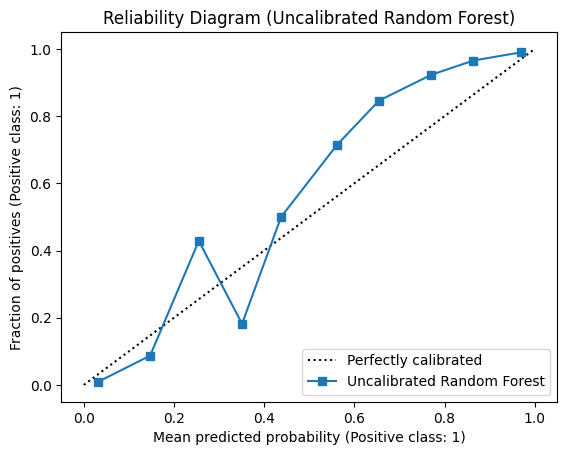

In [21]:
# Train the Random Forest model on training data
spam_rf = create_pipeline(RandomForestClassifier(random_state=SEED), [], spam_feature_cols)
spam_rf.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_rf, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Random Forest")
plt.title("Reliability Diagram (Uncalibrated Random Forest)")
plt.show()

## 4.2. Model Calibration

Unlike Logistic Regression, which naturally outputs calibrated-like probabilities because it optimizes the sigmoid-based Log-Loss, a Random Forest classifier is an ensemble of decision trees. Individual trees output fraction-of-votes probabilities that tend to be pushed away from $0$ and $1$ (resulting in a sigmoidal shape in its reliability diagram). Therefore, both calibration techniques, Platt scaling (`sigmoid`) and `isotonic` regression, are expected to significantly improve the predicted probabilities and lower overall decision costs.

We will run the calibration routine for Random Forest using the same methodology: drawing 100, 250, 500, and 1,000 samples from the calibration set over 50 random draws to observe how calibration size impacts validation costs.

In [22]:
# Run the calibration experiment for Random Forest using our custom function
rf_calibration_results = run_calibration_experiment(
    model=spam_rf,
    X_train=X_spam_train,
    y_train=y_spam_train,
    X_cal=X_spam_cal,
    y_cal=y_spam_cal,
    X_val=X_spam_val,
    y_val=y_spam_val
)

print(rf_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0542  0.0050  0.7836  0.4649  0.0678  0.0108
              250   0.0524  0.0025  0.3855  0.2860  0.0669  0.0069
              500   0.0507  0.0013  0.2303  0.0947  0.0646  0.0053
              1000  0.0512  0.0007  0.1839  0.0099  0.0665  0.0051
     none     0     0.0501     NaN  0.1802     NaN  0.0599     NaN
     sigmoid  100   0.0502  0.0042  0.1831  0.0155  0.0629  0.0061
              250   0.0493  0.0013  0.1784  0.0054  0.0612  0.0033
              500   0.0487  0.0008  0.1754  0.0032  0.0600  0.0019
              1000  0.0487  0.0005  0.1751  0.0020  0.0594  0.0012
5    isotonic 100   0.0542  0.0050  0.7836  0.4649  0.1276  0.0294
              250   0.0524  0.0025  0.3855  0.2860  0.1217  0.0125
              500   0.0507  0.0013  0.2303  0.0947  0.1181  0.

## 4.3. Plotting Costs

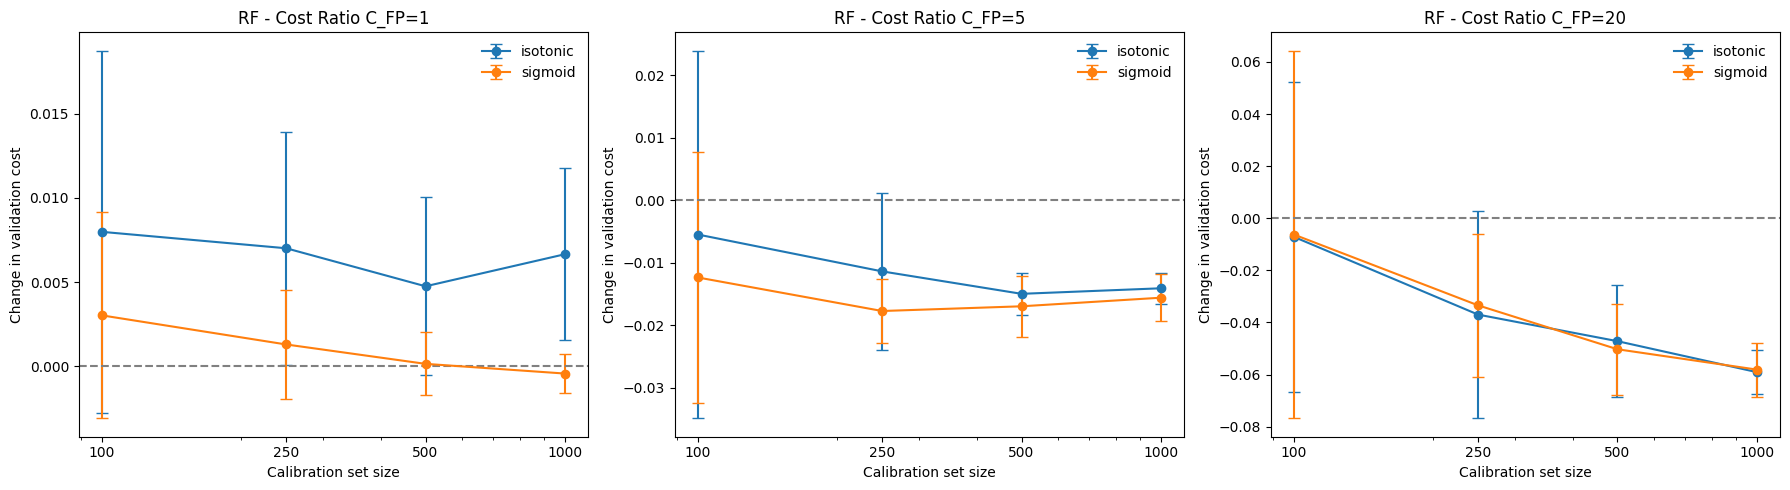

In [23]:
# Plot the change in validation cost for Random Forest
plot_calibration_costs(rf_calibration_results, 'RF')

Analyzing the plots with validation cost change error bars for Random Forest reveals:

- **Sigmoid Calibration (Platt Scaling)**:
  - At a symmetric cost ratio ($C_{FP}=1$), Platt scaling is close to neutral, hovering near the $y=0$ baseline.
  - At higher cost ratios ($C_{FP}=5, 20$), Platt scaling consistently and dramatically lowers validation costs across all sample sizes ($n$), demonstrating that correcting the central-tendency probability distortion of Random Forests is highly beneficial for decision-making under asymmetric costs.

- **Isotonic Calibration**:
  - At symmetric cost ratio ($C_{FP}=1$), Isotonic calibration overfits and yields higher validation costs than the baseline.
  - At higher cost ratios ($C_{FP}=5, 20$), Isotonic calibration successfully reduces validation costs as calibration size increases, eventually matching or outperforming Sigmoid calibration at larger calibration sizes ($n=1000$).

## 4.4. Confidence Interval

In [24]:
# Calculate Bootstrap Confidence Intervals for Random Forest
rf_bootstrap_df = bootstrap_ci(rf_calibration_results, spam_groups, spam_parts)
display(rf_bootstrap_df.round(6))

,c_fp,method,n,mean_difference,95% CI Lower,95% CI Upper,outcome
0,1,sigmoid,100,0.003016,0.002477,0.003592,Increase
1,1,sigmoid,250,0.001286,0.001005,0.001599,Increase
2,1,sigmoid,500,0.000133,-0.000044,0.000302,Tie
3,1,sigmoid,1000,-0.000443,-0.000554,-0.000338,Decrease
4,1,isotonic,100,0.007982,0.006997,0.008968,Increase
5,1,isotonic,250,0.007007,0.006401,0.007679,Increase
6,1,isotonic,500,0.004745,0.004297,0.005264,Increase
7,1,isotonic,1000,0.006652,0.006179,0.007109,Increase
8,5,sigmoid,100,-0.012328,-0.014072,-0.010441,Decrease
9,5,sigmoid,250,-0.017694,-0.018166,-0.017236,Decrease


By aligning the 95% group-paired bootstrap confidence intervals for the cost differences (`calibrated_cost - uncalibrated_cost`) on Random Forest with our plots, we find:

- **Sigmoid Calibration (Platt Scaling)**:
  - At a symmetric cost ratio ($C_{FP}=1$), the 95% CI captures zero at larger sample sizes, classifying the effect as a statistical **Tie** or a small **Decrease** (at $n=1000$).
  - At higher cost ratios ($C_{FP}=5, 20$), Sigmoid calibration results in a statistically significant **Decrease** (improvement) in cost for all sample sizes ($n \ge 100$), confirming that correcting Random Forest voting-fraction biases yields highly robust, statistically significant benefits.

- **Isotonic Calibration**:
  - At symmetric cost ratio ($C_{FP}=1$), the 95% CI is strictly positive for small sample sizes, verifying a statistically significant **Increase** in cost due to overfitting.
  - At higher cost ratios ($C_{FP}=5, 20$), Isotonic calibration achieves a statistically significant **Decrease** in validation costs for larger sample sizes ($n \ge 250$). This confirms that non-parametric calibration successfully outgrows its high-variance limitations given adequate data.

## 4.5. Isotonic Calibration & Random Forest

**Isotonic calibration** is a non-parametric, piece-wise constant model. Because it is highly flexible, it requires a large amount of calibration data to accurately define its steps without overfitting. When calibration sample sizes are small ($n \le 250$), Isotonic calibration overfits to the noise in the calibration subset, producing step-like probability artifacts that lead to severe probability estimation errors. **Platt scaling**, being parametric, is constrained and performs far more robustly on small-to-medium datasets. Hence the reason why Platt scaling performs achieves better cost-performance for **Random Forest** than Isotonic calibration. Random Forest doesn't have the underlying sigmoid-calibration like Logistic Regresion, which avoid the double sigmoid layers from Platt scaling.